# Proyecto 1 Trimestre - Programación Inteligencia Artificial - Daniel Nieto Bouza

El objetivo es conocer las carecteristicas de los clientes e investigar que variables  estan asociadas a la baja de la compañia, ademas entrenaremos varios modelos para ver como predicen y si lo hacen bien que clientes se dan de baja y cuales no, tambien veremos metricas mas avanzadas para ver que modelo es el mejor y por ultimo mdificaremos hiperparametros de los modelos para ver si mejoran o empeoran 

### Importamos las liberiar necesarias para el proyecto y cargamos el dataset en una variable
Despues se mostrarán las primeras filas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clientes = pd.read_csv("./dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")
clientes.head(5)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dimensiones, estructura y tipos de variables del dataset
Vamos a mostra el numero de filas, columas y la información general del dataset

In [3]:
print(f"Numero de filas: {clientes.shape[0]}")
print(f"Numero de columnas: {clientes.shape[1]}")
print("\n Informacion de los datos:")
clientes.info()

Numero de filas: 7043
Numero de columnas: 21

 Informacion de los datos:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-

In [4]:
clientes.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


## Mapear las variables

Este dataset tiene variables categorias que sus valores estan representenado por texto. Para poder utilizar estas variables en los modelos que vamos a implementar despues hay que transformalas a formato numerico.

He utilizado 2 metodos porque nose puedn codificar todas las categorias iguales:

**1. Cofificacion binaria**
En las variables que tienen 2 categorias voy a poner el valor 0 para el No y el 1 para el Yes. Estas variables son: 
**PhoneService, PaperlessBilling, Partner y Dependents** 

**Gender:** 0 para Femenino y 1 para Masculino.

**Y la variable objeto Churn:** En este caso 0 es que el cliente permanece en la empresa y 1 que no permanece

**2. Codificacion con One-hot Encoding**

Voy a utilizarlo en variables que tengan mas de 2 categorias. Este metodo vcrea una nueva columna para cada categoría, asignando un 1 cuando el registro pertenece a ella y un 0 cuando no.

In [5]:
# Creo una copia del dataset para trabajar con ella y no modificar el original
clientes_copia = clientes.copy()

### Codificacion de las variables binarias

In [6]:
variables_binarias = ["PhoneService", "PaperlessBilling", "Partner", "Dependents"]

for variable in variables_binarias:
    clientes_copia[variable] = clientes_copia[variable].map(
        {"Yes": 1,
         "No": 0
        })


clientes_copia["gender"] = clientes_copia["gender"].map(
    {"Male": 1,
     "Female": 0
    })

clientes_copia["Churn"] = clientes_copia["Churn"].map(
    {"Yes": 1, 
     "No": 0
    })

### Codificacion con One-Hot Encoding

In [7]:
variables_categoricas = ["MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaymentMethod"]

clientes_copia = pd.get_dummies(
    clientes_copia,
    columns=variables_categoricas,
    drop_first=False,
    dtype=int
)

### Vamos a eliminar de esta copia el costumerID ya que no aporta ninguna informacion al dataset

In [8]:
clientes_copia = clientes_copia.drop(columns=["customerID"])

In [9]:
clientes_copia

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.5,0,...,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,1,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,84.80,1990.5,0,...,0,0,1,0,1,0,0,0,0,1
7039,0,0,1,1,72,1,1,103.20,7362.9,0,...,0,0,1,0,1,0,0,1,0,0
7040,0,0,1,1,11,0,1,29.60,346.45,0,...,1,0,0,1,0,0,0,0,1,0
7041,1,1,1,0,4,1,1,74.40,306.6,1,...,1,0,0,1,0,0,0,0,0,1


## Variables del dataset

Las columas mas interesantes para el analisis son:



## Revisamos los tipos de datos

In [10]:
print("Tipos de datos del dataset:")
clientes_copia.dtypes

Tipos de datos del dataset:


gender                                       int64
SeniorCitizen                                int64
Partner                                      int64
Dependents                                   int64
tenure                                       int64
PhoneService                                 int64
PaperlessBilling                             int64
MonthlyCharges                             float64
TotalCharges                                   str
Churn                                        int64
MultipleLines_No                             int64
MultipleLines_No phone service               int64
MultipleLines_Yes                            int64
InternetService_DSL                          int64
InternetService_Fiber optic                  int64
InternetService_No                           int64
OnlineSecurity_No                            int64
OnlineSecurity_No internet service           int64
OnlineSecurity_Yes                           int64
OnlineBackup_No                

### Cambio de tipo de TotalCharge (de str a float64)

En este caso vemos que TotalCharges (El total de los cargos hechos por el cliente en la compañia), está como str, voy a cambiarlo para que sea float64 para que sea mas facil hacer calculos con esa variable

In [11]:
clientes_copia['TotalCharges'] = pd.to_numeric(
    clientes_copia['TotalCharges'], 
    errors='coerce'
)

print(clientes_copia["TotalCharges"].dtypes)

clientes['TotalCharges'] = pd.to_numeric(
    clientes['TotalCharges'], 
    errors='coerce'
)

print(clientes["TotalCharges"].dtypes)

float64
float64


## Gestionamos los valores nulos

In [12]:

ausentes = clientes_copia.isnull().sum()
print("Valores ausentes en el dataset: ")
print(ausentes)

## Mostramos en lso clientes que tienen valores nulos cuantos meses (tenure) y cuantos cargos menuslaes (MonthleCjarges) tienen.
clientes_copia[clientes_copia["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]

Valores ausentes en el dataset: 
gender                                      0
SeniorCitizen                               0
Partner                                     0
Dependents                                  0
tenure                                      0
PhoneService                                0
PaperlessBilling                            0
MonthlyCharges                              0
TotalCharges                               11
Churn                                       0
MultipleLines_No                            0
MultipleLines_No phone service              0
MultipleLines_Yes                           0
InternetService_DSL                         0
InternetService_Fiber optic                 0
InternetService_No                          0
OnlineSecurity_No                           0
OnlineSecurity_No internet service          0
OnlineSecurity_Yes                          0
OnlineBackup_No                             0
OnlineBackup_No internet service            0
O

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,0
753,0,20.25,NaN,0
936,0,80.85,NaN,0
1082,0,25.75,NaN,0
1340,0,56.05,NaN,0
3331,0,19.85,NaN,0
3826,0,25.35,NaN,0
4380,0,20.00,NaN,0
5218,0,19.70,NaN,0
6670,0,73.35,NaN,0


Como vemos en la anterior celda los clientes que tienen valores nulos en TotalCharge llevan 0 meses en la empresa. Lo que voy a hacer es poner en los valores nulos un 0 en cada uno.

In [13]:
clientes_copia["TotalCharges"] = clientes_copia["TotalCharges"].fillna(0)

ausentes = clientes_copia.isnull().sum()
print("Valores ausentes en el dataset: ")
print(ausentes)

Valores ausentes en el dataset: 
gender                                     0
SeniorCitizen                              0
Partner                                    0
Dependents                                 0
tenure                                     0
PhoneService                               0
PaperlessBilling                           0
MonthlyCharges                             0
TotalCharges                               0
Churn                                      0
MultipleLines_No                           0
MultipleLines_No phone service             0
MultipleLines_Yes                          0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
OnlineSecurity_No                          0
OnlineSecurity_No internet service         0
OnlineSecurity_Yes                         0
OnlineBackup_No                            0
OnlineBackup_No internet service           0
OnlineBackup_Yes      

## Gestion de valores duplicados
Comprobamos si hay filas duplicadas en el dataset. En este caso lo que pasa es que la borrar el costumerID los clientes que tienen las mismas caracteristicas piensa que son valores duplicados, pero no es asi. Si hacemos esto con el dataset original nos pondra que no hay valores duplicados. Por eso vamos a conservar las filas duplicadas.

In [14]:
print("Filas duplicadas de clientes_copia(copia del dataset original mapeado para poder entrenar a los modelos):", clientes_copia.duplicated().sum())

print("Filas duplicadas del dataset original:", clientes.duplicated().sum())

Filas duplicadas de clientes_copia(copia del dataset original mapeado para poder entrenar a los modelos): 22
Filas duplicadas del dataset original: 0


## Histogramas
Vamos a mostrar los histrogramas de tenure(Número de meses que el cliente se ha quedado con la empresa), MonthlyCharges (Cargos mensuales de cada cliente) y TotalCharges (cargos totales de cada cliente)

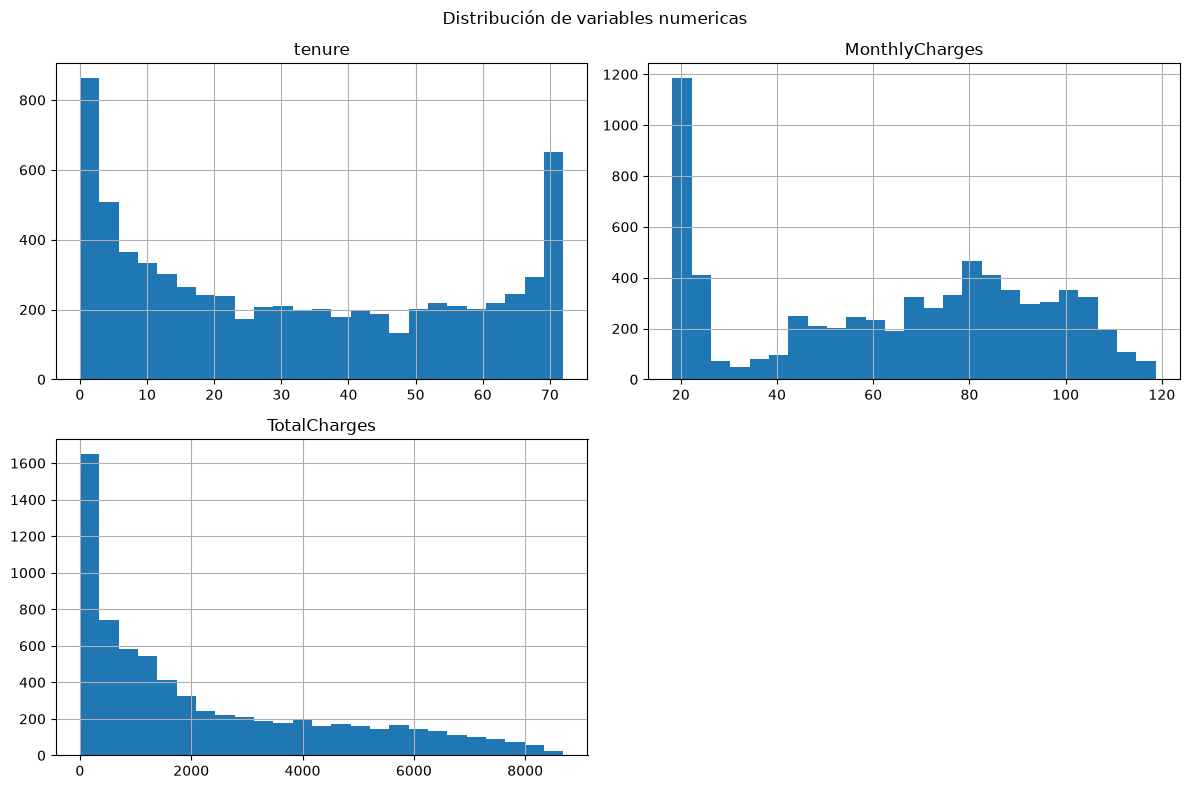

In [15]:
columnas_numericas = ["tenure", "MonthlyCharges", "TotalCharges"]

clientes_copia[columnas_numericas].hist(
    bins=25,
    figsize=(12, 8),
)

plt.suptitle("Distribución de variables numericas")
plt.tight_layout()
plt.show()

### Analisis de las variables numericas segun el abandono

He utilizado diagramas de cajas para comprobar las variables numericas del dataset entre los clientes que abandonan la empresa y los que se quedan.

**Tenure (Meses que llevan los clientes en la empresa):** Se puede ver que hay una mayor concentracion de clientes que abandonan la empresa en los primeros meses en los que etan en la empresa.

**Cargos mensuales:**  Se ve que los que se van de la emprtesa sulen pagar mas al mes con una media de 80€, mientras que los que se quedan en la empresa tienen una media de gasto al mes de unos 65€

**Cragos totales:** Se ve que los que abnadonan la empresa tiene un gasto total menos que los que se quedan, los que se quedan tienen una media de casi 2000€ mientras que los que se van mas o menos de 1000€, aunqie hay muchos outliers con un gasto muy grande

### Viendo estas variables se puede ver que el perfil que abandona la empresa son clientes que llevan poco tiempo en la empresa y que tienen un gasto mensual alto

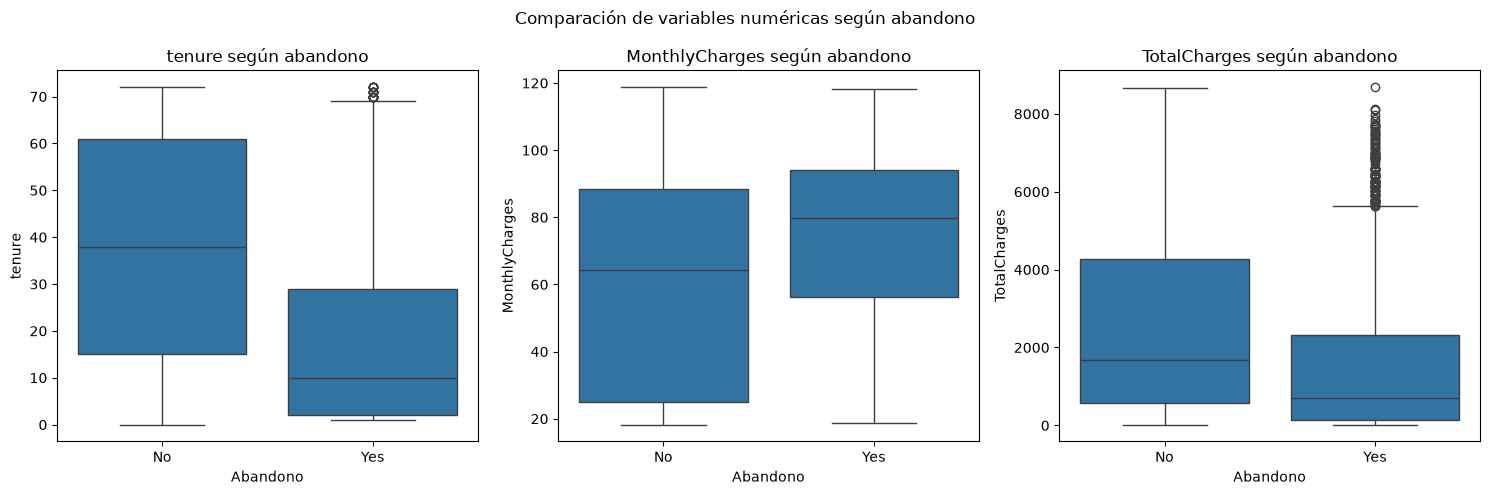

In [16]:
plt.figure(figsize=(15, 5))

for i, variable in enumerate(columnas_numericas, 1):
    plt.subplot(1, 3, i)

    sns.boxplot(
        data=clientes,
        x="Churn",
        y=variable,
        order=["No", "Yes"]
    )

    plt.title(f"{variable} según abandono")
    plt.xlabel("Abandono")
    plt.ylabel(variable)

plt.suptitle("Comparación de variables numéricas según abandono")
plt.tight_layout()
plt.show()

## Estadisticas de las columas numericas

In [17]:
clientes_copia[columnas_numericas].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## Porcentaje en algunas variables

Para hacer los porcentajes vamos a utilizar el dataset original

In [18]:
variables = ["Contract", "InternetService", "PaymentMethod", "gender", "PaperlessBilling", "Churn"]

for variable in variables:

    print(f"\nFrecuencias de {variable}:")

    frecuencias = clientes[variable].value_counts(dropna=False)
    porcentajes = clientes[variable].value_counts(normalize=True, dropna=False) * 100

    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje (%)": porcentajes.round(2)
    })

    display(tabla)


Frecuencias de Contract:


,Frecuencia,Porcentaje (%)
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



Frecuencias de InternetService:


,Frecuencia,Porcentaje (%)
InternetService,,
Fiber optic,3096,43.96
DSL,2421,34.37
No,1526,21.67



Frecuencias de PaymentMethod:


,Frecuencia,Porcentaje (%)
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


... (2 outputs left out)


Frecuencias de PaperlessBilling:


,Frecuencia,Porcentaje (%)
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78



Frecuencias de Churn:


,Frecuencia,Porcentaje (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


## Porcentajes y Analisis del abandono de la empresa a partir de diferentes variables

### Abandono a partir del contrato que tenga cada cliente

Primero vamos a ver que porcentaje total del los clientes tiene contratado cada modalidad de contrato, en este caso se ve que la mayoria de los clientes de la empresa tiene la modalidad de contrato de mes a mes(con un 55%) seguido de la modalidad de 2 años (con un 24%) y por ultimo la modalidad de 1 año (con un 21%)

,Numero de clientes,Porcentaje
Contract,,
Month-to-month,3875,55.02
One year,1473,20.91
Two year,1695,24.07


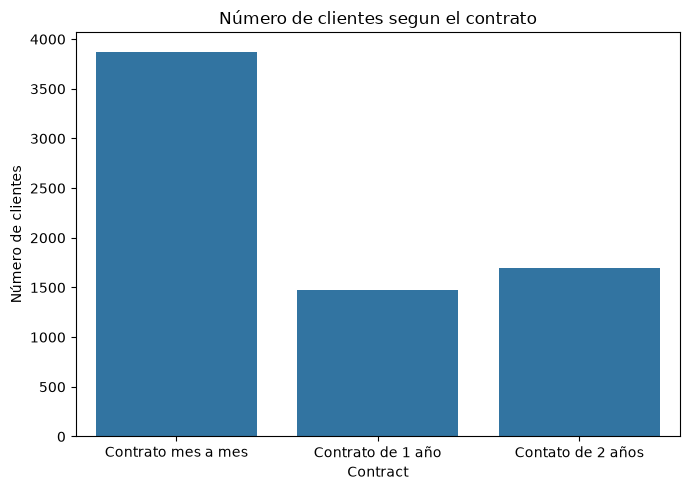

In [19]:
conteo_contrato = clientes["Contract"].value_counts().sort_index()
frecuencia_contrato = clientes["Contract"].value_counts(normalize=True).sort_index() * 100

resumen_contrato = pd.DataFrame({
    "Numero de clientes": conteo_contrato,
    "Porcentaje": frecuencia_contrato.round(2)
})

display(resumen_contrato)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="Contract")
plt.xticks([0, 1, 2], ["Contrato mes a mes", "Contrato de 1 año", "Contato de 2 años"])
plt.title("Número de clientes segun el contrato")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [20]:
def calcular_abandono(variable):
    return (variable == "Yes").mean() * 100

print(f"\nAbandono según el tipo de contrato del cliente:")

conteo_contrato = clientes[clientes["Churn"] == "Yes"]["Contract"].value_counts()
abandono_por_contrato = clientes.groupby("Contract")["Churn"].apply(calcular_abandono).round(2)

abandono_contrato = pd.DataFrame({
    "Numero de clientes": conteo_contrato,
    "Porcentaje": abandono_por_contrato
})

display(abandono_contrato)


Abandono según el tipo de contrato del cliente:


,Numero de clientes,Porcentaje
Contract,,
Month-to-month,1655,42.71
One year,166,11.27
Two year,48,2.83


En esta tabla se ve que el mayor porcentaje de abandono esta el la modalidad de contrato de mes a mes (con un 42,71%), que a su vez es la que mas clientes tiene en la empresa

### Abandono a partir si el cliente tiene contratado internet y de que tipo con la compañia

SE ve que la mayoria de los clientes tiene contratado internet con fibra optica (con un 44%), seguido de los clientes que lo tienen contratado con DSL (con un 34,4%) y por ultimo los clientes que no tiene contratado internet con la compañia (con un 21,7%)

,Numero de clientes,Porcentaje
InternetService,,
DSL,2421,34.37
Fiber optic,3096,43.96
No,1526,21.67


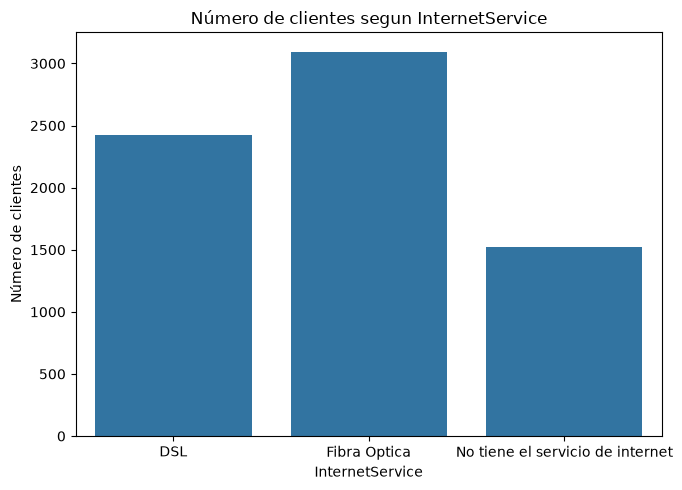

In [21]:
conteo_internet = clientes["InternetService"].value_counts().sort_index()
frecuencia_internet = clientes["InternetService"].value_counts(normalize=True).sort_index() * 100

resumen_internet = pd.DataFrame({
    "Numero de clientes": conteo_internet,
    "Porcentaje": frecuencia_internet.round(2)
})

display(resumen_internet)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="InternetService")
plt.xticks([0, 1, 2], ["DSL", "Fibra Optica", "No tiene el servicio de internet"])
plt.title("Número de clientes segun InternetService")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [22]:
print(f"\nAbandono según si tiene internet y de que tipo:")

conteo_internet = clientes[clientes["Churn"] == "Yes"]["InternetService"].value_counts()
abandono_por_internet = clientes.groupby("InternetService")["Churn"].apply(calcular_abandono).round(2)

abandono_internet = pd.DataFrame({
    "Numero de clientes": conteo_internet,
    "Porcentaje": abandono_por_internet
})

display(abandono_internet)


Abandono según si tiene internet y de que tipo:


,Numero de clientes,Porcentaje
InternetService,,
DSL,459,18.96
Fiber optic,1297,41.89
No,113,7.40


En esta tabla se ve que la mayoria de clientes que abandona la compañia son los que tienen contratado internet con la fibra optica (con un 41,9%), que a su vez es la que mas clientes tienen contratado con la empresa

### Abandono a partir si el cliente tiene contratado TechSuport

Voy a ver primero cuantos clientes tiene cada variable de TechSuport, en este caso la mayoria de clientes no tien contratado el servicio (con un 49,3%), seguido de los que si que lo tienen contratado (con un 29%) y por ultimo los que notienen el servicio de internet (con un 21,7%)

,Numero de clientes,Porcentaje
TechSupport,,
No,3473,49.31
No internet service,1526,21.67
Yes,2044,29.02


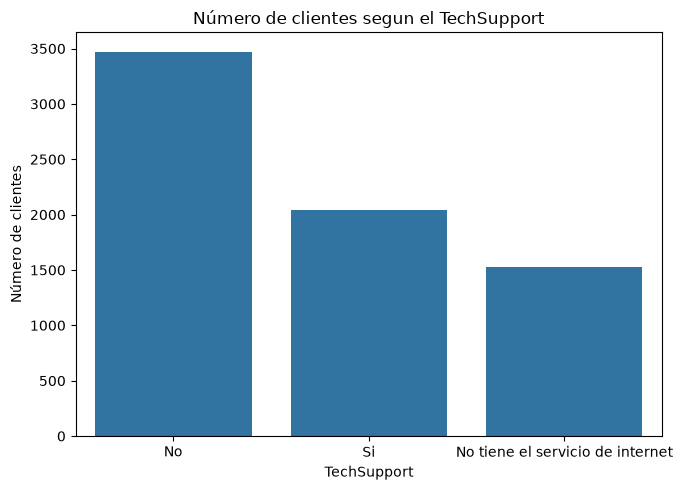

In [23]:
conteo_techSupport = clientes["TechSupport"].value_counts().sort_index()
frecuencia_techSupport = clientes["TechSupport"].value_counts(normalize=True).sort_index() * 100

resumen_techSupport = pd.DataFrame({
    "Numero de clientes": conteo_techSupport,
    "Porcentaje": frecuencia_techSupport.round(2)
})

display(resumen_techSupport)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="TechSupport")
plt.xticks([0, 1, 2], ["No", "Si", "No tiene el servicio de internet"])
plt.title("Número de clientes segun el TechSupport")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [24]:
print(f"\nAbandono según si tiene contratado TechSupport:")

conteo_techSupport = clientes[clientes["Churn"] == "Yes"]["TechSupport"].value_counts()
abandono_por_techSupport = clientes.groupby("TechSupport")["Churn"].apply(calcular_abandono).round(2)

abandono_techSupport = pd.DataFrame({
    "Numero de clientes": conteo_techSupport,
    "Porcentaje": abandono_por_techSupport
})

display(abandono_techSupport)


Abandono según si tiene contratado TechSupport:


,Numero de clientes,Porcentaje
TechSupport,,
No,1446,41.64
No internet service,113,7.40
Yes,310,15.17


En esta tabla se ve que la mayoria de los clientes que abandona la compañia son los que no tienen contratado TechSupport (con un 41,6%)

### Abandono de los clientes a apartir de si tienen facturación si papel o no (PaperlessBilling)

Voy a ver cuantos clientes tiene cada variable de esta categora y el procentaje de esta, en este caso la mayoria si tienen el sistema de facturacion sin papel (un 59%)

,Numero de clientes,Porcentaje
PaperlessBilling,,
No,2872,40.78
Yes,4171,59.22


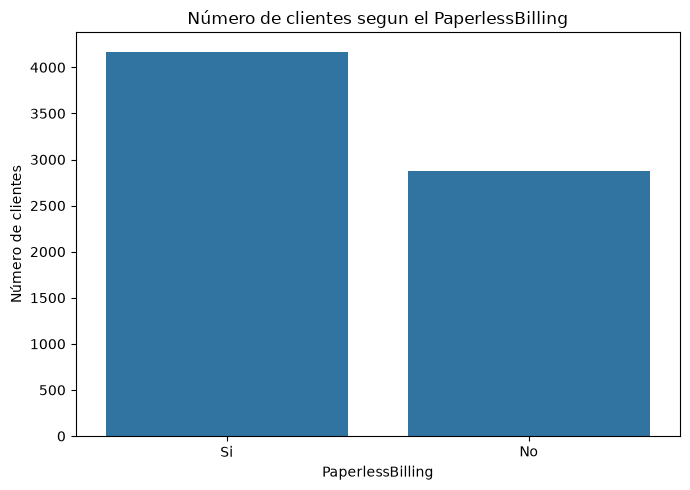

In [25]:
conteo_PaperlessBilling = clientes["PaperlessBilling"].value_counts().sort_index()
frecuencia_PaperlessBilling = clientes["PaperlessBilling"].value_counts(normalize=True).sort_index() * 100

resumen_PaperlessBilling = pd.DataFrame({
    "Numero de clientes": conteo_PaperlessBilling,
    "Porcentaje": frecuencia_PaperlessBilling.round(2)
})

display(resumen_PaperlessBilling)

plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="PaperlessBilling")
plt.xticks([0, 1], ["Si", "No"])
plt.title("Número de clientes segun el PaperlessBilling")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [26]:
print(f"\nAbandono según si tiene contratado PaperlessBilling:")

conteo_PaperlessBilling = clientes[clientes["Churn"] == "Yes"]["PaperlessBilling"].value_counts()
abandono_por_PaperlessBilling = clientes.groupby("PaperlessBilling")["Churn"].apply(calcular_abandono).round(2)

abandono_PaperlessBilling = pd.DataFrame({
    "Numero de clientes": conteo_PaperlessBilling,
    "Porcentaje": abandono_por_PaperlessBilling
})

display(abandono_PaperlessBilling)


Abandono según si tiene contratado PaperlessBilling:


,Numero de clientes,Porcentaje
PaperlessBilling,,
No,469,16.33
Yes,1400,33.57


### Abandono de los clientes a partir si tienen contratado PhoneService

,Numero de clientes,Porcentaje
PhoneService,,
No,682,9.68
Yes,6361,90.32


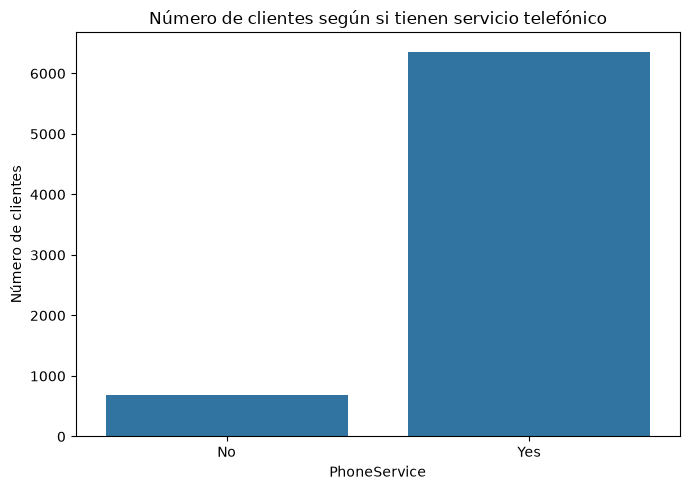

In [27]:
conteo_PhoneService = clientes["PhoneService"].value_counts().sort_index()
frecuencia_PhoneService = clientes["PhoneService"].value_counts(normalize=True).sort_index() * 100

resumen_PhoneService = pd.DataFrame({
    "Numero de clientes": conteo_PhoneService,
    "Porcentaje": frecuencia_PhoneService.round(2)
})

display(resumen_PhoneService)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="PhoneService")
plt.title("Número de clientes según si tienen servicio telefónico")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [28]:
print(f"\nAbandono según si tiene contratado PhoneService:")

conteo_PhoneService = clientes[clientes["Churn"] == "Yes"]["PhoneService"].value_counts()
abandono_por_PhoneService = clientes.groupby("PhoneService")["Churn"].apply(calcular_abandono).round(2)

abandono_PhoneService = pd.DataFrame({
    "Numero de clientes": conteo_PhoneService,
    "Porcentaje": abandono_por_PhoneService
})

display(abandono_PhoneService)


Abandono según si tiene contratado PhoneService:


,Numero de clientes,Porcentaje
PhoneService,,
No,170,24.93
Yes,1699,26.71


En esta tabla se ve el porcentaje de abandono dependiendo si tienen o no contartado en servicio de telefonia esta muy igualado (con un 25/26% de tasa de abandono en los dos casos)

### Abandono de los clientes a partir si tienen contratado varias lineas de telefono (MultipleLines)

,Numero de clientes,Porcentaje
MultipleLines,,
No,3390,48.13
No phone service,682,9.68
Yes,2971,42.18


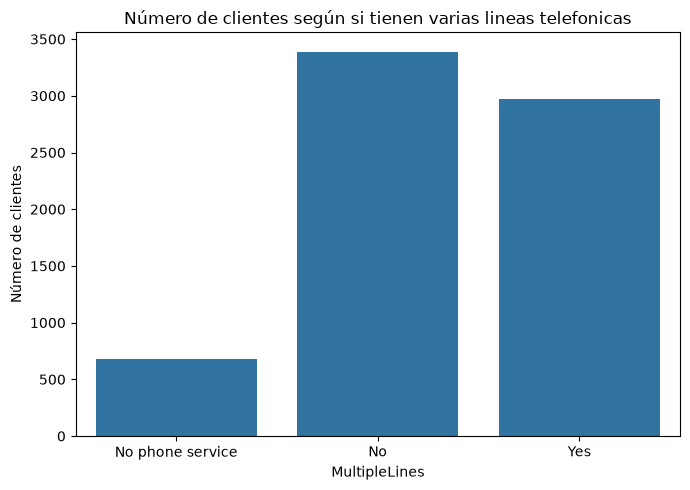

In [29]:
conteo_MultipleLines = clientes["MultipleLines"].value_counts().sort_index()
frecuencia_MultipleLines = clientes["MultipleLines"].value_counts(normalize=True).sort_index() * 100

resumen_MultipleLines = pd.DataFrame({
    "Numero de clientes": conteo_MultipleLines,
    "Porcentaje": frecuencia_MultipleLines.round(2)
})

display(resumen_MultipleLines)


plt.figure(figsize=(7, 5))
sns.countplot(data=clientes, x="MultipleLines")
plt.title("Número de clientes según si tienen varias lineas telefonicas")
plt.ylabel("Número de clientes")
plt.tight_layout()
plt.show()

In [30]:
print(f"\nAbandono según si tiene contratado varias lineas telefoicas (MultipeLines):")

conteo_MultipleLines = clientes[clientes["Churn"] == "Yes"]["MultipleLines"].value_counts()
abandono_por_MultipleLines = clientes.groupby("MultipleLines")["Churn"].apply(calcular_abandono).round(2)

abandono_MultipleLines = pd.DataFrame({
    "Numero de clientes": conteo_MultipleLines,
    "Porcentaje": abandono_por_MultipleLines
})

display(abandono_MultipleLines)


Abandono según si tiene contratado varias lineas telefoicas (MultipeLines):


,Numero de clientes,Porcentaje
MultipleLines,,
No,849,25.04
No phone service,170,24.93
Yes,850,28.61


### Analisis de abandono por tramo de antiguedad en la empresa

Vamos a crear varios tramos de meses de antiguedad que lleva el cliente en la empresa para poder hacer un analisis  de abandono de la empresa

In [31]:
def tipo_antiguedad(meses):
    if meses <= 6:
        return "0-6 meses"
    elif meses <= 12:
        return "7 meses-1 año"
    elif meses <= 24:
        return "Mas de 1 año-2 años"
    elif meses < 48:
        return "Mas de 2 años-3 años"
    else:
        return "Mas de 3 años"



In [32]:
clientes_copia["Tramo_antiguedad"] = clientes_copia["tenure"].apply(tipo_antiguedad)

In [33]:
clientes_copia

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Tramo_antiguedad
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,1,0,0,0,0,1,0,0-6 meses
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,1,0,0,0,0,1,Mas de 2 años-3 años
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,1,0,0,0,0,0,1,0-6 meses
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,0,0,0,1,0,1,0,0,0,Mas de 2 años-3 años
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,1,0,0,0,0,1,0,0-6 meses
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,0,1,1,24,1,1,84.80,1990.50,0,...,0,1,0,1,0,0,0,0,1,Mas de 1 año-2 años
7039,0,0,1,1,72,1,1,103.20,7362.90,0,...,0,1,0,1,0,0,1,0,0,Mas de 3 años
7040,0,0,1,1,11,0,1,29.60,346.45,0,...,0,0,1,0,0,0,0,1,0,7 meses-1 año
7041,1,1,1,0,4,1,1,74.40,306.60,1,...,0,0,1,0,0,0,0,0,1,0-6 meses


In [34]:
def calcular_abandono(variable):
    return (variable == 1).mean() * 100

print("\nAbandono según el tramo de antigüedad (Tramo_antiguedad):")

conteo_abandonos = clientes_copia[
    clientes_copia["Churn"] == 1
]["Tramo_antiguedad"].value_counts()

abandono_por_TramosAntiguedad = clientes_copia.groupby(
    "Tramo_antiguedad"
)["Churn"].apply(calcular_abandono).round(2)

abandono_TramoAntiguedad = pd.DataFrame({
    "Numero de clientes": conteo_abandonos,
    "Porcentaje": abandono_por_TramosAntiguedad
})

display(abandono_TramoAntiguedad)



Abandono según el tramo de antigüedad (Tramo_antiguedad):


,Numero de clientes,Porcentaje
Tramo_antiguedad,,
0-6 meses,784,52.94
7 meses-1 año,253,35.89
Mas de 1 año-2 años,294,28.71
Mas de 2 años-3 años,316,20.65
Mas de 3 años,222,9.64


## Matriz de Correlación de variables numerias

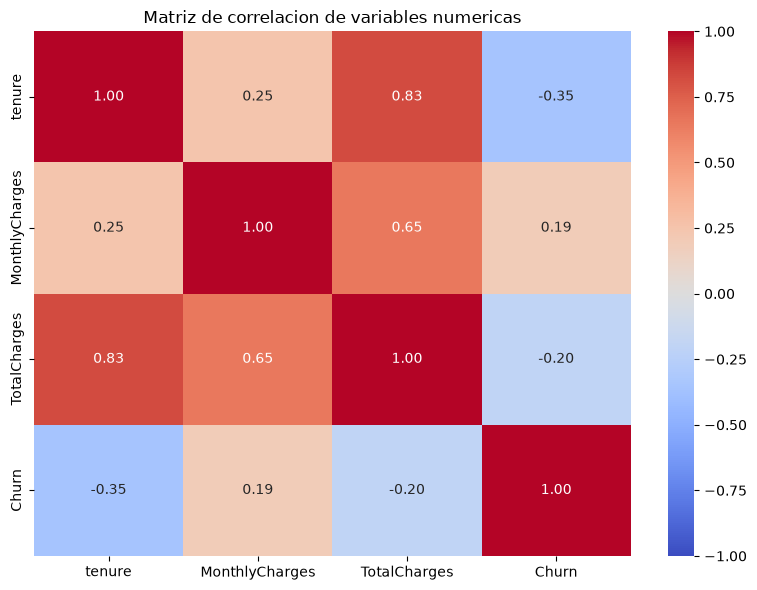

In [35]:
columnas_corr = [c for c in ["tenure", "MonthlyCharges", "TotalCharges", "Churn"] if c in clientes_copia.columns]
corr = clientes_copia[columnas_corr].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlacion de variables numericas")
plt.tight_layout()
plt.show()

## Matriz de Correlacion de otras variables


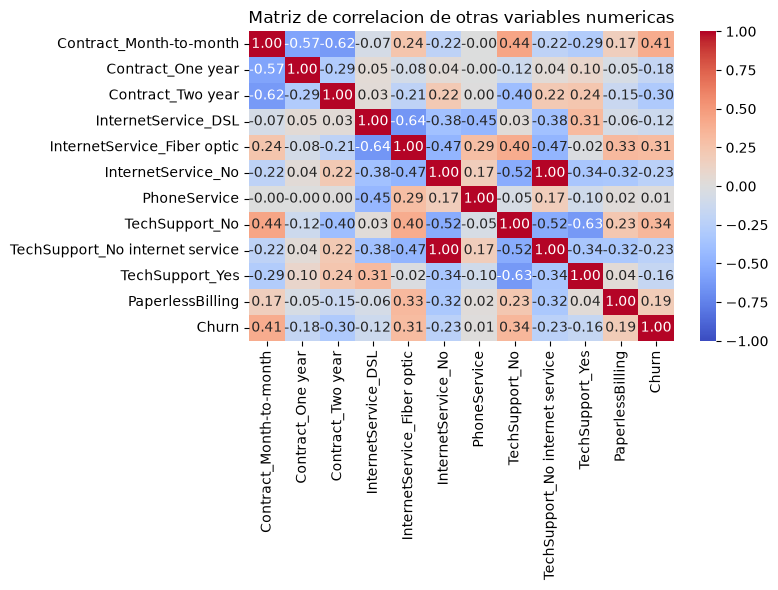

In [36]:
columnas_corr = [c for c in ["Contract_Month-to-month", "Contract_One year", "Contract_Two year", "InternetService_DSL", "InternetService_Fiber optic", "InternetService_No", "PhoneService", 'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes', "PaperlessBilling", "Churn"] if c in clientes_copia.columns]
corr = clientes_copia[columnas_corr].astype(float).corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, fmt=".2f")
plt.title("Matriz de correlacion de otras variables numericas")
plt.tight_layout()

En esta matriz de correlacion general se ve cuales son las caracteristicas mas importantes se puede ver cuales tiene mas relacion con el abando de de la empresa.

### Conclusiones finales del EDA

Vemos que hay un total de 7.043 clientes en el dataset, de los cuales un 26,54% ha abandonado la empresa y un 73,46% sigue en la empresa.

En cuanto a las variables relacionadas con el abandono destacan las siguientes:

**Tipo de contrato:** Los clientes con contratos mensuales tienen una tasa de abandono del 42,71% frente al 11,27% de los contratos de 1 año y al 2,83% de los contratos de 2 años. por eso, parece existir una relacion importante entre la relacion del contrato con el abandono o permanecia en la empresa.

**Servicio de Internet:** Los clientes que tienen contratada la fibra optica con la empresa tienen una tasa de abandono del 41,89%, los clientes que tienen contratado DSL el abandono es del 18,96% y los clientes que no tienen contratado Internet el abandono es del 7,40%.

**Soprte Tecnico:** Los clientes que no tienen contratado el soporte tecnico tienen una tasa de abandono del 41,64% mientras los que si que lo tienen es del 15,17%

**Facturacion sin papel:** Los clientes que utilizan este sistema tienen una tasa de abandono del 33,57% frente al 16,33% de los clientes que no lo utilizan.

**Antigüedad del cliente en la empresa:** Los clientes que llevan de 0 a 6 meses en la empresa tiene una tasa de abandono del 52,94%, el porcentaje disminiye porgresivamente mientra aumenta la antigüedad del cliente en la empresa. Por eso esta es una de las variables que para mi, tiene un arelacion mas clara con el abandono de la empresa.

Tambien he observado que los clientes que tienen unos caragos mensuales altos, con una media de 80€, mientras que los clientes quepermanenecen tienen una media inferior de 65€.

Este analisis las variables que estan mas relacionadas con el abandono de clientes son la antigüedad en la empresa, el tipo de contrato que tienen los clientes, el servicio de internet contratado, tener o no contratado el soporte tecnico con la empresa y los cargos mensulaes de cada cliente.

## Entrenamiento de modelos

## Regresión Logistica

### Seleccionar las carecteristicas

Como vamos a predecir si un cliente abandona o no la empresa, esto es un porblema de clasificación binaria, por eso tenemos que utilizar la regresión logistica y no la regresión lineal

Lo primero que vamos a hacer es dividir las columnas en variables caracteristicas y variable objetivo (en este caso Churn)

En X vamos a quitar ademas de la variable objetivo (Churn) la variable tramo_antiguedad ya que es una variable redundante de la variable tenure (meses que lleva el cliente en la empresa)

In [37]:
from sklearn.linear_model import LogisticRegression

X = clientes_copia.drop(columns=["Churn", "Tramo_antiguedad"])
y = clientes_copia["Churn"]

### Dividimos los datos

Vamos a dividir el dataset en 2 partes, conjunto de prueba y conjunto de entrenamiento.

Ponemos un test_size de 0.3 para que el 70% sea para entrenamiento y el otro 30% para probar si el modelo es bueno

Vamos a utilizar el stratify para que haya la misma proporcion de clientes que abandonan y clientes que permanecen en la empresa

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

### Vamos a estandarizar las variables

La regresion logistica funciona mejor cuando las variables numericas tienen escalas o valores parecidos. Tenure puede llegar a valores maximos de 100, mientras que MonthlyCharges y TotalCharges llegan avalores de decenas, centenas e incluso miles.

Vamos a utilizar StandardScaler para solucionarlo, utilizo transform en X_test porque utiliza los mismos parametros que ha utilizado fit_transform con X_test para transformar el conjunto de prueba y no haya fuga de informacion.

In [39]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_escalado = scaler.fit_transform(X_train)
X_test_escalado = scaler.transform(X_test)

### Entrenamos el modelos de Regresión Logistica

In [40]:
modelo_regresionLogistica = LogisticRegression()
modelo_regresionLogistica.fit(X_train_escalado, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

### Realizamos las predicciones

In [41]:
y_pred = modelo_regresionLogistica.predict(X_test_escalado)

### Evaluacion del modelo

### Accuracy
Vamos a calcular el accuracy (precision) del modelo y vamos a hacer la matriz de confusión para ver que tipos de errores hace el modelo a la hora de predecir si el cliente abandona la empresa o se queda

In [ ]:
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score, classification_report,
                             roc_auc_score, RocCurveDisplay, average_precision_score,
                             PrecisionRecallDisplay, precision_recall_curve)

accuracyRegresionLogistica = accuracy_score(y_test, y_pred)

print(f"Accuracy (Precisión) del modelo de Regresión Logística: {accuracyRegresionLogistica:.4f}")

Accuracy (Precisión) del modelo de Regresión Logística: 0.8093


### Matriz de Confusión

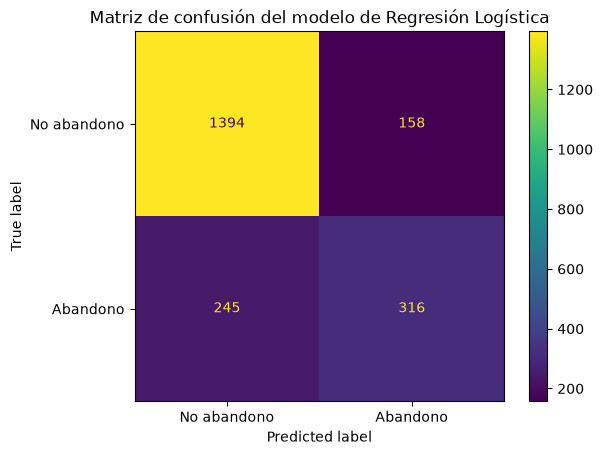

In [43]:
cm_regresion_logistica = ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred),
    display_labels=["No abandono", "Abandono"]
    ).plot()

plt.title("Matriz de confusión del modelo de Regresión Logística")
plt.show()  

El modelo identifica bien a 1394 clientes que no abandonan pero predice que 158 clientes abandonan y no lo hacen

Tambien no consigue detectar a 245 clientes que si que abandonan e identifica a 316 clientes que abandonan

### Conclusiones de la matriz de confusion

El modelo identifica bastante bien a los clientes que permanencen en la empresa pero tiene mas problemas para detectar a los clientes que abandonan la empresa.

### Precision, recall y F1

Precison mide cuantos clientes que hemos identificado como posible abandono realmente abandonan la empresa

Recall mide cuantos de los clientes que abandonan consigue detectarlos el modelo

F1-score combina las dos en una medida

In [44]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1-score:", round(f1, 3))

Precision: 0.667
Recall: 0.563
F1-score: 0.611


In [46]:
print(classification_report(y_test, y_pred, target_names=["No abandona", "Abandona"]))

              precision    recall  f1-score   support

 No abandona       0.85      0.90      0.87      1552
    Abandona       0.67      0.56      0.61       561

    accuracy                           0.81      2113
   macro avg       0.76      0.73      0.74      2113
weighted avg       0.80      0.81      0.80      2113



### Conclusiones de los resultados

Si nos fijamos solo en el accuracy que hicimos al principio diriamos que el modelo predice bastante bien que clientes abandonan y que clientes permanecen en la empresa, pero si hacemos la matriz de confusión y otras metricas mas precisas nos damos cuenta que este modelo tiene bastantes fallos en lo mas importante para mi, que es detectar que clientes abandonan la empresa.

## KNN

Vamos a importar el clasificador KNN, ademas deberiamos escalar las variables, peroc omo ya he hecho eso para el modelo de regresión logística lo voy a reultilizar tambien en este.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

#Inicio el clasificador
clasificador_KNN = KNeighborsClassifier(n_neighbors=5)

# Lo entrenamos
clasificador_KNN.fit(X_train_escalado, y_train)

# Realizo las predicciones sobre el conjunto de prueba

predicciones_KNN = clasificador_KNN.predict(X_test_escalado)

### Evaluamos el modelo

Vamos a utilizar las mismas metricas de evaluación, primero el accuracy y luego la matriz de confusión, precision, recall y F1

In [ ]:
accuracyKNN = accuracy_score(y_test, predicciones_KNN)